In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Village Digital Twin is ready!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Matplotlib is building the font cache; this may take a moment.


Village Digital Twin is ready!
Pandas version: 3.1.1
NumPy version: 2.5.5


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the downloaded dataset
file_path = "../data/raw/waterconsumption_noNaN_fixedTimechange.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head(10))

Dataset loaded successfully!
Number of rows and columns: (46032, 6)


,Date,Time,Consumption,Temperature,Rain,Sun
0,1/1/2016,00:00-01:00,1480,0.6,0.0,0
1,1/1/2016,01:00-02:00,1362,0.6,0.0,0
2,1/1/2016,02:00-03:00,1296,0.5,0.0,0
3,1/1/2016,03:00-04:00,1096,0.0,0.0,0
4,1/1/2016,04:00-05:00,810,0.3,0.0,0
5,1/1/2016,05:00-06:00,474,1.0,1.0,0
6,1/1/2016,06:00-07:00,586,1.9,0.0,0
7,1/1/2016,07:00-08:00,437,2.7,0.0,0
8,1/1/2016,08:00-09:00,1004,2.9,0.0,0
9,1/1/2016,09:00-10:00,1652,3.4,0.0,0


In [2]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Column names:
['Date', 'Time', 'Consumption', 'Temperature', 'Rain', 'Sun']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 46032 entries, 0 to 46031
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         46032 non-null  str    
 1   Time         46032 non-null  str    
 2   Consumption  46032 non-null  int64  
 3   Temperature  46032 non-null  float64
 4   Rain         46007 non-null  float64
 5   Sun          46032 non-null  int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 2.1 MB

Missing values:
Date            0
Time            0
Consumption     0
Temperature     0
Rain           25
Sun             0
dtype: int64

Statistical summary:


,Consumption,Temperature,Rain,Sun
count,46032.000000,46032.000000,46007.000000,46032.000000
mean,2314.342544,10.799741,0.050079,1.677333
std,1032.138095,7.763414,0.375667,2.883667
min,1.000000,-17.600000,0.000000,0.000000
25%,1461.000000,5.000000,0.000000,0.000000
50%,2550.000000,10.100000,0.000000,0.000000
75%,3082.000000,16.200000,0.000000,2.000000
max,6514.000000,40.300000,22.000000,20.000000


In [3]:
print(df.head())
print("\nData types:")
print(df.dtypes)

       Date           Time  Consumption  Temperature  Rain  Sun
0  1/1/2016   00:00-01:00          1480          0.6   0.0    0
1  1/1/2016   01:00-02:00          1362          0.6   0.0    0
2  1/1/2016   02:00-03:00          1296          0.5   0.0    0
3  1/1/2016   03:00-04:00          1096          0.0   0.0    0
4  1/1/2016   04:00-05:00           810          0.3   0.0    0

Data types:
Date               str
Time               str
Consumption      int64
Temperature    float64
Rain           float64
Sun              int64
dtype: object


In [4]:
print(df.columns.tolist())
display(df.head())

['Date', 'Time', 'Consumption', 'Temperature', 'Rain', 'Sun']


,Date,Time,Consumption,Temperature,Rain,Sun
0,1/1/2016,00:00-01:00,1480,0.6,0.0,0
1,1/1/2016,01:00-02:00,1362,0.6,0.0,0
2,1/1/2016,02:00-03:00,1296,0.5,0.0,0
3,1/1/2016,03:00-04:00,1096,0.0,0.0,0
4,1/1/2016,04:00-05:00,810,0.3,0.0,0


In [5]:

# Work on a copy of the original dataset
hourly_df = df.copy()

# Convert Date column into proper datetime format
hourly_df["Date"] = pd.to_datetime(
    hourly_df["Date"],
    dayfirst=True,
    errors="coerce"
)

# Convert measurement columns into numeric values
for col in ["Consumption", "Temperature", "Rain", "Sun"]:
    hourly_df[col] = pd.to_numeric(
        hourly_df[col],
        errors="coerce"
    )

# Check for invalid dates
print("Invalid dates:", hourly_df["Date"].isna().sum())

# Remove rows with invalid dates or consumption
hourly_df = hourly_df.dropna(
    subset=["Date", "Consumption"]
)

# Group hourly measurements by date
daily_df = hourly_df.groupby(
    hourly_df["Date"].dt.normalize()
).agg(
    daily_consumption=("Consumption", "sum"),
    avg_temperature=("Temperature", "mean"),
    daily_rain=("Rain", "sum"),
    daily_sun_total=("Sun", "sum"),
    avg_sun=("Sun", "mean"),
    hourly_records=("Consumption", "count")
).reset_index()

# Rename the date column
daily_df.rename(columns={"Date": "date"}, inplace=True)

print("Daily dataset created!")
print("Daily records:", len(daily_df))

display(daily_df.head(10))


Invalid dates: 27864
Daily dataset created!
Daily records: 757


C:\Users\DHRUVI\AppData\Local\Temp\ipykernel_30560\2484301747.py:39: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  daily_df.rename(columns={"Date": "date"}, inplace=True)


,date,daily_consumption,avg_temperature,daily_rain,daily_sun_total,avg_sun,hourly_records
0,2016-01-01,41759,3.158333,1.0,7,0.291667,24
1,2016-01-02,52185,11.000000,7.0,3,0.125000,24
2,2016-01-03,49846,0.425000,0.0,34,1.416667,24
3,2016-01-04,50510,7.633333,0.0,62,2.583333,24
4,2016-01-05,45595,9.537500,1.0,73,3.041667,24
5,2016-01-06,47477,17.304167,12.0,22,0.916667,24
6,2016-01-07,51549,19.529167,0.0,48,2.000000,24
7,2016-01-08,51567,15.462500,2.0,57,2.375000,24
8,2016-01-09,53665,17.987500,0.0,62,2.583333,24
9,2016-01-10,46501,12.829167,0.0,15,0.625000,24


In [6]:
# Start again from the original dataset
hourly_df = df.copy()

# Handle mixed date formats
hourly_df["Date"] = pd.to_datetime(
    hourly_df["Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Check the result
print("Total rows:", len(hourly_df))
print("Valid dates:", hourly_df["Date"].notna().sum())
print("Invalid dates:", hourly_df["Date"].isna().sum())

# Display examples of dates that still failed
print("\nInvalid date examples:")
display(df.loc[hourly_df["Date"].isna(), ["Date"]].head(20))

Total rows: 46032
Valid dates: 46032
Invalid dates: 0

Invalid date examples:


,Date


In [7]:
# Convert measurement columns into numeric values
for col in ["Consumption", "Temperature", "Rain", "Sun"]:
    hourly_df[col] = pd.to_numeric(
        hourly_df[col],
        errors="coerce"
    )

# Group hourly records by date
daily_df = hourly_df.groupby(
    hourly_df["Date"].dt.normalize()
).agg(
    daily_consumption=("Consumption", "sum"),
    avg_temperature=("Temperature", "mean"),
    daily_rain=("Rain", "sum"),
    daily_sun_total=("Sun", "sum"),
    avg_sun=("Sun", "mean"),
    hourly_records=("Consumption", "count")
).reset_index()

# Rename date column
daily_df = daily_df.rename(
    columns={"Date": "date"}
)

print("Daily dataset created!")
print("Total daily records:", len(daily_df))

display(daily_df.head(10))

Daily dataset created!
Total daily records: 1918


,date,daily_consumption,avg_temperature,daily_rain,daily_sun_total,avg_sun,hourly_records
0,2016-01-01,41759,3.158333,1.0,7,0.291667,24
1,2016-01-02,52185,11.000000,7.0,3,0.125000,24
2,2016-01-03,49846,0.425000,0.0,34,1.416667,24
3,2016-01-04,50510,7.633333,0.0,62,2.583333,24
4,2016-01-05,45595,9.537500,1.0,73,3.041667,24
5,2016-01-06,47477,17.304167,12.0,22,0.916667,24
6,2016-01-07,51549,19.529167,0.0,48,2.000000,24
7,2016-01-08,51567,15.462500,2.0,57,2.375000,24
8,2016-01-09,53665,17.987500,0.0,62,2.583333,24
9,2016-01-10,46501,12.829167,0.0,15,0.625000,24


In [8]:
print("Date range:")
print(daily_df["date"].min(), "to", daily_df["date"].max())

print("\nHourly records per day:")
print(daily_df["hourly_records"].value_counts().sort_index())

print("\nMissing values:")
print(daily_df.isnull().sum())

Date range:
2016-01-01 00:00:00 to 2021-12-03 00:00:00

Hourly records per day:
hourly_records
24    1918
Name: count, dtype: int64

Missing values:
date                 0
daily_consumption    0
avg_temperature      0
daily_rain           0
daily_sun_total      0
avg_sun              0
hourly_records       0
dtype: int64


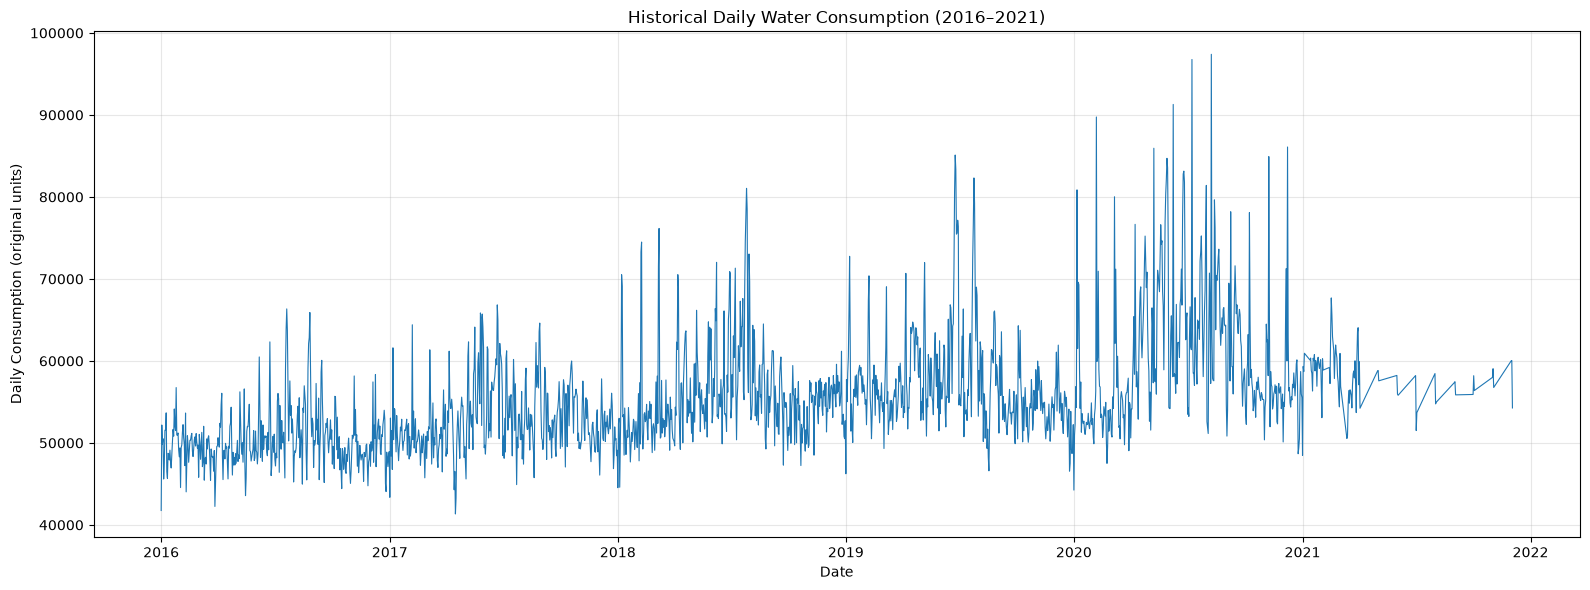

Expected calendar days: 2164
Available daily records: 1918
Missing calendar dates: 246

First missing dates:
DatetimeIndex(['2021-01-05', '2021-01-06', '2021-01-07', '2021-01-08',
               '2021-01-09', '2021-01-10', '2021-01-11', '2021-01-12',
               '2021-02-04', '2021-02-05', '2021-02-06', '2021-02-07',
               '2021-02-08', '2021-02-09', '2021-02-10', '2021-02-11',
               '2021-02-12', '2021-03-04', '2021-03-05', '2021-03-06'],
              dtype='datetime64[us]', freq=None)

Duplicate dates: 0


In [10]:

plt.figure(figsize=(16, 6))

plt.plot(
    daily_df["date"],
    daily_df["daily_consumption"],
    linewidth=0.8
)

plt.title("Historical Daily Water Consumption (2016–2021)")
plt.xlabel("Date")
plt.ylabel("Daily Consumption (original units)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


daily_df = daily_df.sort_values("date").reset_index(drop=True)

expected_dates = pd.date_range(
    start=daily_df["date"].min(),
    end=daily_df["date"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(daily_df["date"])

print("Expected calendar days:", len(expected_dates))
print("Available daily records:", len(daily_df))
print("Missing calendar dates:", len(missing_dates))

print("\nFirst missing dates:")
print(missing_dates[:20])

print("\nDuplicate dates:", daily_df["date"].duplicated().sum())

In [12]:
# Check missing dates year-wise
missing_df = pd.DataFrame({
    "missing_date": missing_dates
})

missing_df["year"] = missing_df["missing_date"].dt.year

print("Missing dates by year:")
print(missing_df.groupby("year").size())

# Check available records by year
print("\nAvailable records by year:")
print(daily_df.groupby(daily_df["date"].dt.year).size())


# Find continuous date ranges in the dataset
date_diff = daily_df["date"].diff().dt.days

daily_df["group"] = (date_diff != 1).cumsum()

periods = daily_df.groupby("group").agg(
    start_date=("date", "min"),
    end_date=("date", "max"),
    total_days=("date", "count")
).reset_index(drop=True)

periods = periods.sort_values(
    "total_days",
    ascending=False
)

print("Continuous data periods:")
display(periods.head(15))

Missing dates by year:
year
2021    246
dtype: int64

Available records by year:
date
2016    366
2017    365
2018    365
2019    365
2020    366
2021     91
dtype: int64
Continuous data periods:


,start_date,end_date,total_days
0,2016-01-01,2021-01-04,1831
1,2021-01-13,2021-02-03,22
3,2021-03-13,2021-04-03,22
2,2021-02-13,2021-03-03,19
4,2021-05-01,2021-05-03,3
5,2021-06-01,2021-06-03,3
6,2021-07-01,2021-07-03,3
7,2021-08-01,2021-08-03,3
8,2021-09-01,2021-09-03,3
9,2021-10-01,2021-10-03,3


In [13]:

# Select the longest continuous period
model_df = daily_df[
    (daily_df["date"] >= "2016-01-01") &
    (daily_df["date"] <= "2021-01-04")
].copy()

# Remove temporary grouping column
model_df = model_df.drop(
    columns=["group"],
    errors="ignore"
)

# Reset row numbering
model_df = model_df.reset_index(drop=True)

print("Final modelling dataset created!")

print("Total records:", len(model_df))
print("Start date:", model_df["date"].min())
print("End date:", model_df["date"].max())

print("\nMissing values:")
print(model_df.isnull().sum())

display(model_df.head())


Final modelling dataset created!
Total records: 1831
Start date: 2016-01-01 00:00:00
End date: 2021-01-04 00:00:00

Missing values:
date                 0
daily_consumption    0
avg_temperature      0
daily_rain           0
daily_sun_total      0
avg_sun              0
hourly_records       0
dtype: int64


,date,daily_consumption,avg_temperature,daily_rain,daily_sun_total,avg_sun,hourly_records
0,2016-01-01,41759,3.158333,1.0,7,0.291667,24
1,2016-01-02,52185,11.000000,7.0,3,0.125000,24
2,2016-01-03,49846,0.425000,0.0,34,1.416667,24
3,2016-01-04,50510,7.633333,0.0,62,2.583333,24
4,2016-01-05,45595,9.537500,1.0,73,3.041667,24


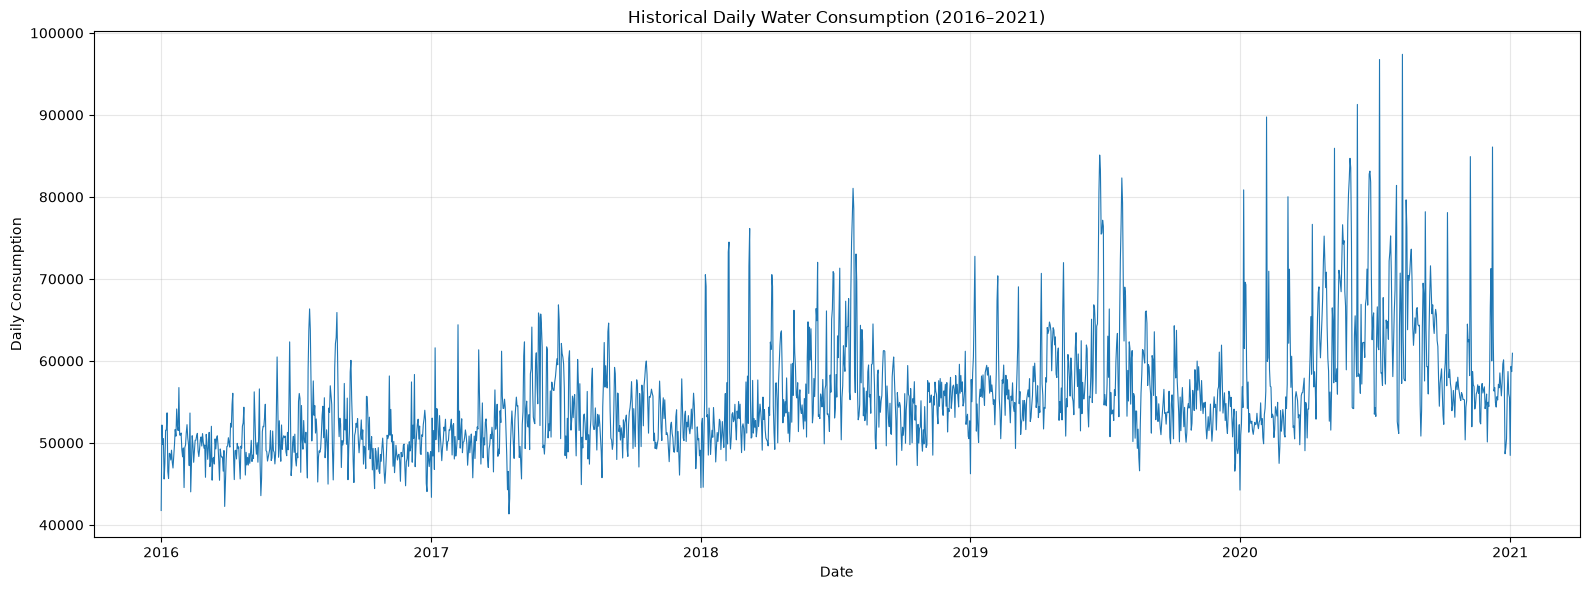

In [14]:
plt.figure(figsize=(16, 6))

plt.plot(
    model_df["date"],
    model_df["daily_consumption"],
    linewidth=0.8
)

plt.title("Historical Daily Water Consumption (2016–2021)")
plt.xlabel("Date")
plt.ylabel("Daily Consumption")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
model_df.to_csv(
    "../data/processed/final_daily_water_demand.csv",
    index=False
)

print("Final modelling dataset saved successfully!")

Final modelling dataset saved successfully!


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

model_df = pd.read_csv(
    "../data/processed/final_daily_water_demand.csv"
)

model_df["date"] = pd.to_datetime(model_df["date"])

model_df = model_df.sort_values("date").reset_index(drop=True)

print("Dataset loaded:", model_df.shape)
display(model_df.head())

Dataset loaded: (1831, 7)


,date,daily_consumption,avg_temperature,daily_rain,daily_sun_total,avg_sun,hourly_records
0,2016-01-01,41759,3.158333,1.0,7,0.291667,24
1,2016-01-02,52185,11.000000,7.0,3,0.125000,24
2,2016-01-03,49846,0.425000,0.0,34,1.416667,24
3,2016-01-04,50510,7.633333,0.0,62,2.583333,24
4,2016-01-05,45595,9.537500,1.0,73,3.041667,24


In [17]:
# Calculate the 80% training point
split_index = int(len(model_df) * 0.80)

# Split chronologically
train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting period:")
print(test_df["date"].min(), "to", test_df["date"].max())

Training records: 1464
Testing records: 367

Training period:
2016-01-01 00:00:00 to 2020-01-03 00:00:00

Testing period:
2020-01-04 00:00:00 to 2021-01-04 00:00:00


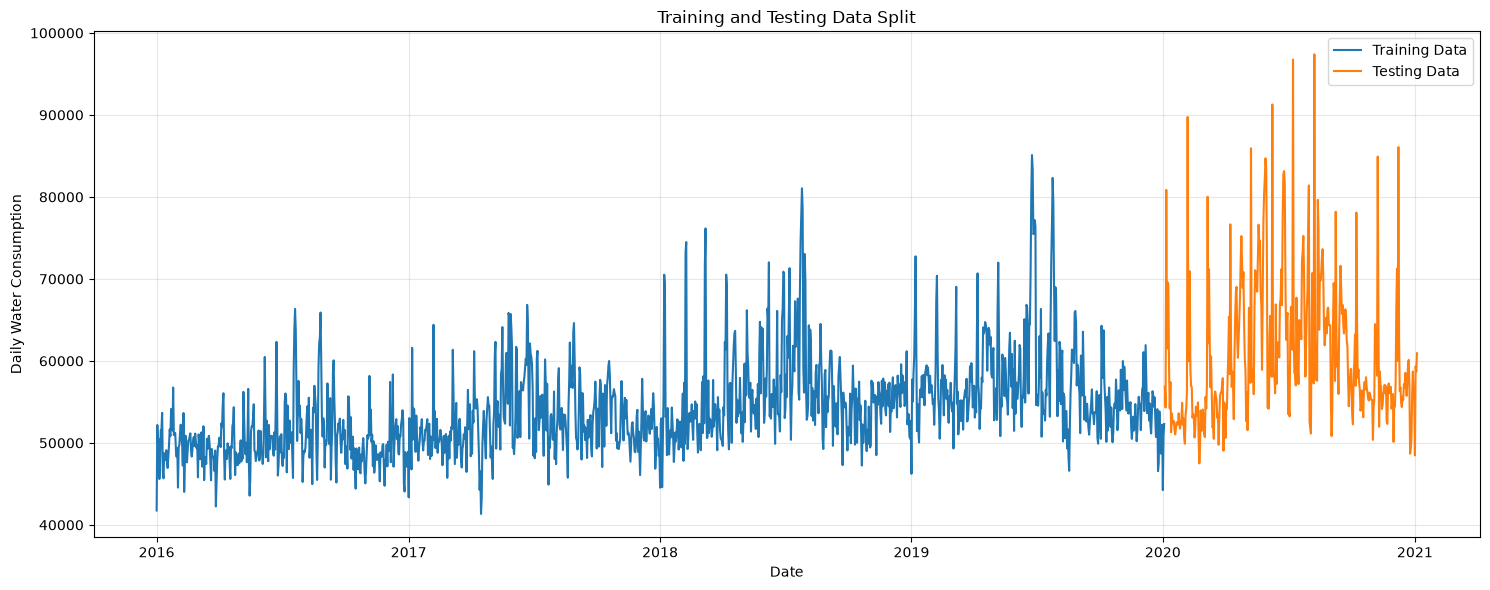

In [18]:
plt.figure(figsize=(15, 6))

plt.plot(
    train_df["date"],
    train_df["daily_consumption"],
    label="Training Data"
)

plt.plot(
    test_df["date"],
    test_df["daily_consumption"],
    label="Testing Data"
)

plt.title("Training and Testing Data Split")
plt.xlabel("Date")
plt.ylabel("Daily Water Consumption")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
train_df.to_csv(
    "../data/processed/train_data.csv",
    index=False
)

test_df.to_csv(
    "../data/processed/test_data.csv",
    index=False
)

print("Training and testing datasets saved!")

Training and testing datasets saved!


In [20]:

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare training series
train_series = pd.Series(
    train_df["daily_consumption"].values,
    index=pd.date_range(
        start=train_df["date"].min(),
        periods=len(train_df),
        freq="D"
    )
)

# Prepare actual testing values
actual = test_df["daily_consumption"].values

# Train ARIMA model
arima_model = ARIMA(
    train_series,
    order=(1, 1, 1)
)

arima_fit = arima_model.fit()

print(arima_fit.summary())

# Forecast the complete testing period
arima_forecast = arima_fit.forecast(
    steps=len(test_df)
)

# Store predictions
arima_predictions = np.asarray(arima_forecast)

print("\nARIMA training completed!")
print("Number of predictions:", len(arima_predictions))


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1464
Model:                 ARIMA(1, 1, 1)   Log Likelihood              -14195.891
Date:                Thu, 19 Nov 2026   AIC                          28397.783
Time:                        23:03:25   BIC                          28413.647
Sample:                    01-01-2016   HQIC                         28403.700
                         - 01-03-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5642      0.019     29.993      0.000       0.527       0.601
ma.L1         -0.9651      0.007   -130.141      0.000      -0.980      -0.951
sigma2      1.709e+07   4.57e-11   3.74e+17      0.0

In [21]:

# Calculate ARIMA metrics
arima_mae = mean_absolute_error(
    actual, arima_predictions
)

arima_rmse = np.sqrt(
    mean_squared_error(actual, arima_predictions)
)

arima_mape = np.mean(
    np.abs((actual - arima_predictions) / actual)
) * 100

print("ARIMA MODEL PERFORMANCE")
print("-----------------------")
print("MAE:", round(arima_mae, 2))
print("RMSE:", round(arima_rmse, 2))
print("MAPE:", round(arima_mape, 2), "%")


ARIMA MODEL PERFORMANCE
-----------------------
MAE: 8280.05
RMSE: 11622.58
MAPE: 12.23 %


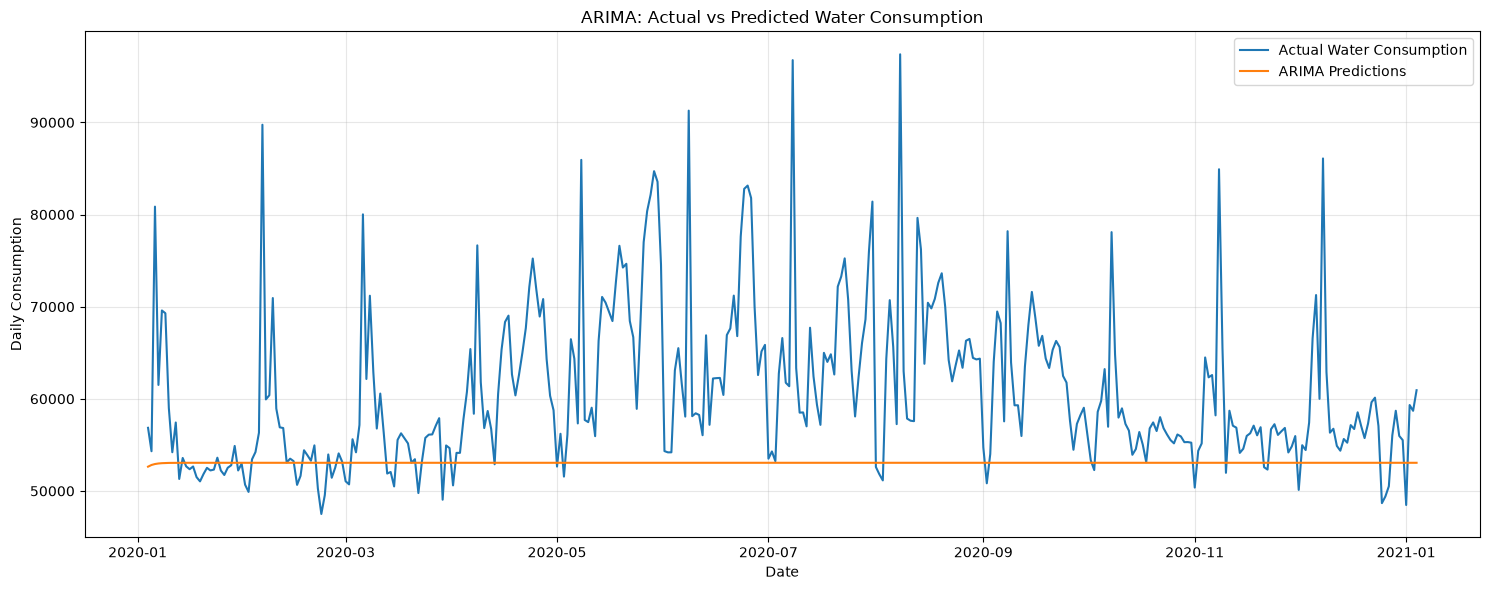

In [22]:
plt.figure(figsize=(15, 6))

plt.plot(
    test_df["date"],
    actual,
    label="Actual Water Consumption"
)

plt.plot(
    test_df["date"],
    arima_predictions,
    label="ARIMA Predictions"
)

plt.title("ARIMA: Actual vs Predicted Water Consumption")
plt.xlabel("Date")
plt.ylabel("Daily Consumption")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# Naive baseline: repeat the last training observation
baseline_predictions = np.repeat(
    train_df["daily_consumption"].iloc[-1],
    len(test_df)
)

baseline_mae = mean_absolute_error(
    actual, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(actual, baseline_predictions)
)

baseline_mape = np.mean(
    np.abs((actual - baseline_predictions) / actual)
) * 100

comparison = pd.DataFrame({
    "Model": ["Naive Baseline", "ARIMA"],
    "MAE": [baseline_mae, arima_mae],
    "RMSE": [baseline_rmse, arima_rmse],
    "MAPE (%)": [baseline_mape, arima_mape]
})

display(comparison.round(2))

,Model,MAE,RMSE,MAPE (%)
0,Naive Baseline,8842.70,12134.64,13.12
1,ARIMA,8280.05,11622.58,12.23


In [25]:
import os
os.makedirs("../results/metrics", exist_ok=True)
os.makedirs("../results/forecasts", exist_ok=True)
os.makedirs("../results/graphs", exist_ok=True)

arima_results = pd.DataFrame({
    "date": test_df["date"].values,
    "actual": actual,
    "arima_predicted": arima_predictions
})

arima_results.to_csv(
    "../results/forecasts/arima_predictions.csv",
    index=False
)

comparison.to_csv(
    "../results/metrics/arima_metrics.csv",
    index=False
)

print("ARIMA results saved successfully!")

ARIMA results saved successfully!


In [26]:
display(comparison.round(2))

,Model,MAE,RMSE,MAPE (%)
0,Naive Baseline,8842.70,12134.64,13.12
1,ARIMA,8280.05,11622.58,12.23


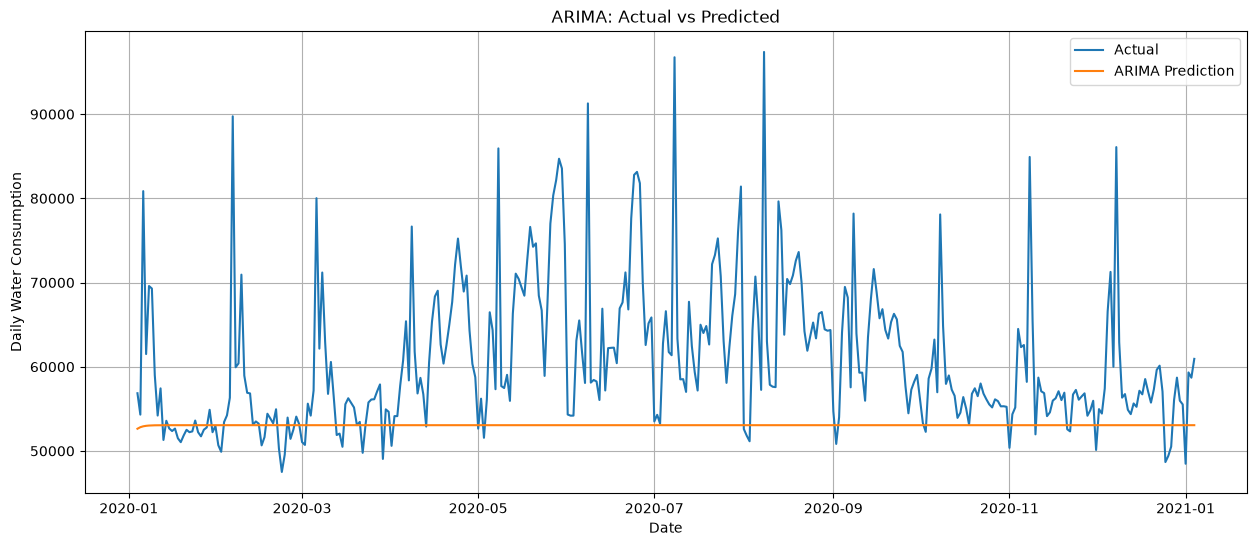

In [27]:
plt.figure(figsize=(15, 6))

plt.plot(test_df["date"], actual, label="Actual")
plt.plot(test_df["date"], arima_predictions, label="ARIMA Prediction")

plt.title("ARIMA: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Daily Water Consumption")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
display(comparison.round(2))

,Model,MAE,RMSE,MAPE (%)
0,Naive Baseline,8842.70,12134.64,13.12
1,ARIMA,8280.05,11622.58,12.23


: 